# CICIoT2023 Feature-Augmented GRU — Five-Seed Final Evaluation

## 1. Environment and reproducibility


In [1]:
# Global reproducibility setup
import os
import random
import numpy as np
import tensorflow as tf

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Global seed set to:", SEED)


Global seed set to: 42


In [18]:
import pandas as pd
import numpy as np
import sklearn, os
from sklearn.preprocessing import StandardScaler # RobustScaler
import matplotlib.pyplot as plt  # for plotting
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve, auc
from tensorflow.keras.optimizers import Adam
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import seaborn as sns 
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import time
from tensorflow.keras.regularizers import l2

## 2. Data preprocessing and feature augmentation

The cells below retain the original preprocessing order and diagnostic outputs.


### Directly clean Augmented data 


In [3]:
# ============================================================
# Load the augmented partitions
train_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Train.csv"
)

validation_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Validation.csv"
)

test_data = pd.read_csv(
    r"/kaggle/input/datasets/zerukifle/ciciot2023-fa-multirun/CICIoT2023_Augmented_Test.csv"
)


print(f"Training data:   {train_data.shape}")
print(f"Validation data: {validation_data.shape}")
print(f"Test data:       {test_data.shape}")

display(train_data.head())


Training data:   (354737, 36)
Validation data: (118246, 36)
Test data:       (118246, 36)


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Drate,fin_flag_number,syn_flag_number,psh_flag_number,ack_flag_number,...,Max,AVG,Tot size,IAT,Covariance,Variance,IF_Anomaly_Score,AE_Anomaly_Score,SUOD_Anomaly_Score,label
0,0.244612,38791.0,17.00,64.00,3202.228500,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83102420.0,0.000000,0.00,0.275168,0.004453,-0.277339,DDoS
1,0.014093,5675.0,17.00,64.00,8785.439000,0.0,0.0,0.0,0.0,0.0,...,50.00,50.00000,50.00,83123740.0,0.000000,0.00,0.283322,0.004197,-0.291433,DDoS
2,0.000000,0.0,47.00,64.00,218.863710,0.0,0.0,0.0,0.0,0.0,...,592.00,592.00000,592.00,83698550.0,0.000000,0.00,0.161012,0.083652,0.648249,Mirai
3,0.000000,54.0,6.00,64.00,3.887012,0.0,0.0,0.0,0.0,0.0,...,54.00,54.00000,54.00,83064136.0,0.000000,0.00,0.319291,0.000523,-0.766263,DDoS
4,0.000000,0.0,0.99,63.36,5.231067,0.0,0.0,0.0,0.0,0.0,...,43.98,42.13838,42.18,83150650.0,2.315749,0.11,0.216951,0.004651,0.238320,DDoS


In [5]:
# ============================================================
# Validate augmented dataset structure
# ============================================================
LABEL_COLUMN = "label"

required_anomaly_features = [
    "IF_Anomaly_Score",
    "AE_Anomaly_Score",
    "SUOD_Anomaly_Score"
]


# Confirm that the label exists in every partition
for dataset_name, dataset in {
    "Training": train_data,
    "Validation": validation_data,
    "Test": test_data
}.items():

    if LABEL_COLUMN not in dataset.columns:
        raise KeyError(
            f"'{LABEL_COLUMN}' was not found in the "
            f"{dataset_name} dataset."
        )


# Extract training feature names
feature_columns = [
    column
    for column in train_data.columns
    if column != LABEL_COLUMN
]


# Confirm that all anomaly-score features exist
missing_anomaly_features = [
    feature
    for feature in required_anomaly_features
    if feature not in feature_columns
]

if missing_anomaly_features:
    raise KeyError(
        "Missing anomaly-score features: "
        f"{missing_anomaly_features}"
    )


# Confirm that all partitions contain identical features
validation_feature_columns = [
    column
    for column in validation_data.columns
    if column != LABEL_COLUMN
]

test_feature_columns = [
    column
    for column in test_data.columns
    if column != LABEL_COLUMN
]

if set(feature_columns) != set(validation_feature_columns):
    raise ValueError(
        "Training and validation feature columns do not match."
    )

if set(feature_columns) != set(test_feature_columns):
    raise ValueError(
        "Training and test feature columns do not match."
    )


print("Dataset validation completed successfully.")
print(f"Number of augmented features: {len(feature_columns)}")
print(f"Training instances: {len(train_data):,}")
print(f"Validation instances: {len(validation_data):,}")
print(f"Test instances: {len(test_data):,}")

print("\nAnomaly-score features:")
for feature in required_anomaly_features:
    print(f"- {feature}")


Dataset validation completed successfully.
Number of augmented features: 35
Training instances: 354,737
Validation instances: 118,246
Test instances: 118,246

Anomaly-score features:
- IF_Anomaly_Score
- AE_Anomaly_Score
- SUOD_Anomaly_Score


### Separate augmented features and multiclass labels


In [6]:
# import numpy as np

# from sklearn.preprocessing import LabelEncoder


# ============================================================
# Extract augmented feature matrices
# ============================================================
# feature_columns were defined in the validation cell.
# Selecting these columns preserves the training column order.
X_train = train_data[
    feature_columns
].copy()

X_val = validation_data[
    feature_columns
].copy()

X_test = test_data[
    feature_columns
].copy()


# ============================================================
# Validate numeric feature values
# ============================================================
for dataset_name, feature_data in {
    "Training": X_train,
    "Validation": X_val,
    "Test": X_test
}.items():

    non_numeric_columns = feature_data.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    if non_numeric_columns:
        raise TypeError(
            f"{dataset_name} data contain non-numeric "
            f"features: {non_numeric_columns}"
        )

    if not np.isfinite(
        feature_data.to_numpy(dtype=np.float32)
    ).all():
        raise ValueError(
            f"{dataset_name} features contain missing "
            "or infinite values."
        )


# ============================================================
# Extract original multiclass labels
# ============================================================
y_train_original = (
    train_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_val_original = (
    validation_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)

y_test_original = (
    test_data[LABEL_COLUMN]
    .astype(str)
    .str.strip()
)


print(f"Training features:   {X_train.shape}")
print(f"Validation features: {X_val.shape}")
print(f"Test features:       {X_test.shape}")

print(
    f"\nNumber of training classes: "
    f"{y_train_original.nunique()}"
)

display(y_train_original.value_counts())


Training features:   (354737, 35)
Validation features: (118246, 35)
Test features:       (118246, 35)

Number of training classes: 8


label
DDoS          258100
DoS            61405
Mirai          20231
Benign          8248
Spoofing        3729
Recon           2736
Web              188
BruteForce       100
Name: count, dtype: int64

#### Encode the multiclass labels


In [7]:
# ============================================================
# Fit the label encoder on training labels only
# ============================================================
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(
    y_train_original
)


# ============================================================
# Check for unknown validation or test classes
# ============================================================
training_classes = set(
    label_encoder.classes_
)

unknown_validation_classes = (
    set(y_val_original.unique())
    - training_classes
)

unknown_test_classes = (
    set(y_test_original.unique())
    - training_classes
)

if unknown_validation_classes:
    raise ValueError(
        "Validation data contain classes that are absent "
        f"from training: {sorted(unknown_validation_classes)}"
    )

if unknown_test_classes:
    raise ValueError(
        "Test data contain classes that are absent "
        f"from training: {sorted(unknown_test_classes)}"
    )


# Transform validation and test labels using the same encoder
y_val = label_encoder.transform(
    y_val_original
)

y_test = label_encoder.transform(
    y_test_original
)


# ============================================================
# Display multiclass mapping
# ============================================================
print("Multiclass label mapping:")

for class_code, class_name in enumerate(
    label_encoder.classes_
):
    print(f"{class_code}: {class_name}")


number_of_classes = len(
    label_encoder.classes_
)

print(
    f"\nNumber of multiclass target classes: "
    f"{number_of_classes}"
)


Multiclass label mapping:
0: Benign
1: BruteForce
2: DDoS
3: DoS
4: Mirai
5: Recon
6: Spoofing
7: Web

Number of multiclass target classes: 8


#### Standardize the augmented features


In [8]:
from sklearn.preprocessing import StandardScaler


# ============================================================
# Fit the scaler on augmented training features only
# ============================================================
classifier_scaler = StandardScaler()

X_train_scaled = classifier_scaler.fit_transform(
    X_train
).astype(np.float32)


# Apply the same fitted scaler without refitting
X_val_scaled = classifier_scaler.transform(
    X_val
).astype(np.float32)

X_test_scaled = classifier_scaler.transform(
    X_test
).astype(np.float32)


# ============================================================
# Verify scaled data
# ============================================================
if not np.isfinite(X_train_scaled).all():
    raise ValueError(
        "Scaled training features contain invalid values."
    )

if not np.isfinite(X_val_scaled).all():
    raise ValueError(
        "Scaled validation features contain invalid values."
    )

if not np.isfinite(X_test_scaled).all():
    raise ValueError(
        "Scaled test features contain invalid values."
    )


print(f"Scaled training features:   {X_train_scaled.shape}")
print(f"Scaled validation features: {X_val_scaled.shape}")
print(f"Scaled test features:       {X_test_scaled.shape}")

print(
    f"\nTraining mean after scaling: "
    f"{X_train_scaled.mean():.6f}"
)

print(
    f"Training standard deviation after scaling: "
    f"{X_train_scaled.std():.6f}"
)


Scaled training features:   (354737, 35)
Scaled validation features: (118246, 35)
Scaled test features:       (118246, 35)

Training mean after scaling: 0.000000
Training standard deviation after scaling: 1.000000


## 3. Gated Recurrent Unit Network (GRU)

### Prepare the GRU input representation

The original GRU input-variable names are retained.


In [9]:
# Preserve the original one-time-step representation, using scaled inputs.
input_attribute_count = X_train_scaled.shape[1]

X_train_reshaped_GRU = X_train_scaled.reshape(
    -1, 1, input_attribute_count
)
X_val_reshaped_GRU = X_val_scaled.reshape(
    -1, 1, input_attribute_count
)
X_test_reshaped_GRU = X_test_scaled.reshape(
    -1, 1, input_attribute_count
)

print(f"GRU training shape:   {X_train_reshaped_GRU.shape}")
print(f"GRU validation shape: {X_val_reshaped_GRU.shape}")
print(f"GRU test shape:       {X_test_reshaped_GRU.shape}")


GRU training shape:   (354737, 1, 35)
GRU validation shape: (118246, 1, 35)
GRU test shape:       (118246, 1, 35)


### Optional GRU hyperparameter optimization

The original GRU Optuna structure is retained for future use.

- Keep `RUN_OPTUNA = False` for the current 5-seed final experiment.
  The previously stored optimized GRU parameters are loaded.
- Change `RUN_OPTUNA = True` only when you want to perform a new
  hyperparameter search.




In [11]:
# ============================================================
# GRU optimization control
# ============================================================

import json
import os

# False -> use previously stored optimized parameters.
# True  -> run a new Optuna search and save new parameters.
RUN_OPTUNA = True

N_OPTUNA_TRIALS = 25


# ------------------------------------------------------------
# Existing optimized parameters
# Kaggle input directories are read-only.
# ------------------------------------------------------------
PRESTORED_PARAMS_GRU_FILE = (
    "/kaggle/input/datasets/zerukifle/"
    "ciciot2023-fa-multirun/"
    "best_params_gru_03_TVTF_SUDO_V3.json"
)


# ------------------------------------------------------------
# Newly optimized parameters
# Kaggle working directory is writable.
# ------------------------------------------------------------
NEW_PARAMS_GRU_FILE = (
    "/kaggle/working/"
    "best_params_gru_imbalanceCIC2023.json"
)


print(
    "RUN_OPTUNA:",
    RUN_OPTUNA,
)

print(
    "Number of Optuna trials:",
    N_OPTUNA_TRIALS,
)

if RUN_OPTUNA:
    print(
        "New optimized GRU parameters will be saved to:",
        NEW_PARAMS_GRU_FILE,
    )
else:
    print(
        "Pre-stored GRU parameters will be loaded from:",
        PRESTORED_PARAMS_GRU_FILE,
    )


RUN_OPTUNA: True
Number of Optuna trials: 25
New optimized GRU parameters will be saved to: /kaggle/working/best_params_gru_imbalanceCIC2023.json


In [12]:
from sklearn.metrics import f1_score
from tensorflow.keras import regularizers
from tensorflow.keras.layers import (
    GRU,
    Dense,
    Dropout,
    Input,
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam


class SparseMacroF1(tf.keras.metrics.Metric):
    """Dataset-level macro F1 for sparse integer multiclass labels."""

    def __init__(
        self,
        number_of_classes,
        name="macro_f1",
        **kwargs,
    ):
        super().__init__(
            name=name,
            **kwargs,
        )

        self.number_of_classes = int(
            number_of_classes
        )

        self.confusion_matrix = self.add_weight(
            name="confusion_matrix",
            shape=(
                self.number_of_classes,
                self.number_of_classes,
            ),
            initializer="zeros",
            dtype=tf.float32,
        )

    def update_state(
        self,
        y_true,
        y_pred,
        sample_weight=None,
    ):
        y_true = tf.cast(
            tf.reshape(
                y_true,
                [-1],
            ),
            tf.int32,
        )

        y_pred = tf.argmax(
            y_pred,
            axis=1,
            output_type=tf.int32,
        )

        weights = None

        if sample_weight is not None:
            weights = tf.cast(
                tf.reshape(
                    sample_weight,
                    [-1],
                ),
                tf.float32,
            )

        batch_confusion_matrix = (
            tf.math.confusion_matrix(
                y_true,
                y_pred,
                num_classes=(
                    self.number_of_classes
                ),
                weights=weights,
                dtype=tf.float32,
            )
        )

        self.confusion_matrix.assign_add(
            batch_confusion_matrix
        )

    def result(self):
        true_positives = (
            tf.linalg.diag_part(
                self.confusion_matrix
            )
        )

        false_positives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=0,
            )
            - true_positives
        )

        false_negatives = (
            tf.reduce_sum(
                self.confusion_matrix,
                axis=1,
            )
            - true_positives
        )

        class_f1 = tf.math.divide_no_nan(
            2.0 * true_positives,
            2.0 * true_positives
            + false_positives
            + false_negatives,
        )

        return tf.reduce_mean(
            class_f1
        )

    def reset_state(self):
        self.confusion_matrix.assign(
            tf.zeros_like(
                self.confusion_matrix
            )
        )

    def get_config(self):
        config = super().get_config()

        config.update(
            {
                "number_of_classes":
                    self.number_of_classes
            }
        )

        return config


In [13]:
# ============================================================
# Recommended GRU Optuna objective and search space
# ============================================================

MAX_EPOCHS_GRU = 100
EARLY_STOPPING_PATIENCE = 10


def objective_gru(trial):
    """Train one GRU trial and return validation macro F1."""

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        SEED + trial.number
    )

    # --------------------------------------------------------
    # Architecture-specific recurrent-unit search space
    # --------------------------------------------------------
    hidden_layer1_gru = trial.suggest_int(
        "hidden_layer1_gru",
        32,
        128,
        step=16,
    )

    hidden_layer2_gru = trial.suggest_int(
        "hidden_layer2_gru",
        16,
        64,
        step=16,
    )

    # --------------------------------------------------------
    # Shared optimization search space
    # --------------------------------------------------------
    dropout_rate_gru = trial.suggest_float(
        "dropout_rate_gru",
        0.1,
        0.4,
        step=0.1,
    )

    l2_reg_gru = trial.suggest_float(
        "l2_reg_gru",
        1e-6,
        1e-3,
        log=True,
    )

    batch_size_gru = trial.suggest_categorical(
        "batch_size_gru",
        [64, 128, 256],
    )

    learning_rate_gru = trial.suggest_float(
        "learning_rate_gru",
        1e-5,
        1e-2,
        log=True,
    )

    model_gru_trial = Sequential(
        [
            Input(
                shape=(
                    1,
                    input_attribute_count,
                )
            ),

            GRU(
                hidden_layer1_gru,
                return_sequences=True,
                kernel_regularizer=l2(
                    l2_reg_gru
                ),
            ),

            Dropout(
                dropout_rate_gru
            ),

            GRU(
                hidden_layer2_gru,
                return_sequences=False,
                kernel_regularizer=l2(
                    l2_reg_gru
                ),
            ),

            Dropout(
                dropout_rate_gru
            ),

            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=l2(
                    l2_reg_gru
                ),
            ),
        ],
        name="GRU_Optuna_Trial",
    )

    model_gru_trial.compile(
        loss="sparse_categorical_crossentropy",

        optimizer=Adam(
            learning_rate=(
                learning_rate_gru
            )
        ),

        metrics=[
            "accuracy",

            SparseMacroF1(
                number_of_classes
            ),
        ],
    )

    model_gru_trial.fit(
        X_train_reshaped_GRU,
        y_train,

        epochs=MAX_EPOCHS_GRU,

        batch_size=batch_size_gru,

        validation_data=(
            X_val_reshaped_GRU,
            y_val,
        ),

        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
            ),

            KerasPruningCallback(
                trial,
                monitor="val_macro_f1",
                interval=1,
            ),
        ],

        shuffle=True,
        verbose=0,
    )

    validation_probabilities = (
        model_gru_trial.predict(
            X_val_reshaped_GRU,
            verbose=0,
        )
    )

    validation_predictions = np.argmax(
        validation_probabilities,
        axis=1,
    )

    validation_macro_f1 = f1_score(
        y_val,
        validation_predictions,

        labels=np.arange(
            number_of_classes
        ),

        average="macro",
        zero_division=0,
    )

    del model_gru_trial

    tf.keras.backend.clear_session()

    return float(
        validation_macro_f1
    )


In [16]:
# !pip install optuna-integration[keras]

In [19]:
# ============================================================
# Execute optional Optuna optimization
# ============================================================

if RUN_OPTUNA:

    import optuna
    from optuna.trial import TrialState

    # Current Optuna versions provide integrations through
    # optuna-integration. The fallback supports older versions.
    try:
        from optuna_integration import (
            KerasPruningCallback
        )
    except ImportError:
        from optuna.integration import (
            KerasPruningCallback
        )

    # TPE sampling and median-based early pruning.
    study_gru = optuna.create_study(
        direction="maximize",
        sampler=(
            optuna.samplers.TPESampler(
                seed=SEED
            )
        ),
        pruner=(
            optuna.pruners.MedianPruner(
                n_startup_trials=5,
                n_warmup_steps=10,
                interval_steps=1,
            )
        ),
    )

    study_gru.optimize(
        objective_gru,
        n_trials=N_OPTUNA_TRIALS,
        n_jobs=1,
        gc_after_trial=True,
    )

    complete_trials_gru = (
        study_gru.get_trials(
            deepcopy=False,
            states=[
                TrialState.COMPLETE
            ],
        )
    )

    pruned_trials_gru = (
        study_gru.get_trials(
            deepcopy=False,
            states=[
                TrialState.PRUNED
            ],
        )
    )

    failed_trials_gru = (
        study_gru.get_trials(
            deepcopy=False,
            states=[
                TrialState.FAIL
            ],
        )
    )

    print(
        "Best GRU hyperparameters:",
        study_gru.best_params,
    )

    print(
        "Best GRU validation macro F1: "
        f"{study_gru.best_value:.6f}"
    )

    print(
        "GRU study statistics:"
    )

    print(
        "  Number of finished trials:",
        len(
            study_gru.trials
        ),
    )

    print(
        "  Number of complete trials:",
        len(
            complete_trials_gru
        ),
    )

    print(
        "  Number of pruned trials:",
        len(
            pruned_trials_gru
        ),
    )

    print(
        "  Number of failed trials:",
        len(
            failed_trials_gru
        ),
    )

    best_trial_gru = (
        study_gru.best_trial
    )

    print(
        "  Best validation macro F1: "
        f"{best_trial_gru.value:.6f}"
    )

    print(
        "  Best parameters:"
    )

    for (
        key,
        value,
    ) in best_trial_gru.params.items():
        print(
            f"    {key}: {value}"
        )

    # Preserve the original variable name.
    best_params_gru_03_TVTF_SUDO_V3 = (
        study_gru.best_params
    )

    with open(
        NEW_PARAMS_GRU_FILE,
        "w",
        encoding="utf-8",
    ) as json_file:
        json.dump(
            best_params_gru_03_TVTF_SUDO_V3,
            json_file,
            indent=2,
        )

    print(
        "New optimized GRU parameters saved to:",
        NEW_PARAMS_GRU_FILE,
    )

else:
    print(
        "Optuna optimization skipped. "
        "Using the pre-stored GRU parameters."
    )


[I 2026-09-25 22:34:33,368] A new study created in memory with name: no-name-9e4556ec-3b2a-43b6-882e-9906a3cd534e
2026-09-25 22:34:33.648834: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
[I 2026-09-25 22:44:05,592] Trial 0 finished with value: 0.6341768733233919 and parameters: {'hidden_layer1_gru': 64, 'hidden_layer2_gru': 64, 'dropout_rate_gru': 0.30000000000000004, 'l2_reg_gru': 6.251373574521755e-05, 'batch_size_gru': 64, 'learning_rate_gru': 0.003967605077052989}. Best is trial 0 with value: 0.6341768733233919.
[I 2026-09-25 23:40:48,449] Trial 1 finished with value: 0.5876971613042323 and parameters: {'hidden_layer1_gru': 96, 'hidden_layer2_gru': 48, 'dropout_rate_gru': 0.1, 'l2_reg_gru': 0.0008123245085588687, 'batch_size_gru': 64, 'learning_rate_gru': 3.5498788321965036e-05}. Best is trial 0 with value: 0.6341768733233919.
[I 2026-09-26 00:30:19,138] Trial 2 finished wi

Best GRU hyperparameters: {'hidden_layer1_gru': 128, 'hidden_layer2_gru': 32, 'dropout_rate_gru': 0.2, 'l2_reg_gru': 1.1321021804230381e-06, 'batch_size_gru': 64, 'learning_rate_gru': 0.0011769044926591633}
Best GRU validation macro F1: 0.722628
GRU study statistics:
  Number of finished trials: 25
  Number of complete trials: 12
  Number of pruned trials: 13
  Number of failed trials: 0
  Best validation macro F1: 0.722628
  Best parameters:
    hidden_layer1_gru: 128
    hidden_layer2_gru: 32
    dropout_rate_gru: 0.2
    l2_reg_gru: 1.1321021804230381e-06
    batch_size_gru: 64
    learning_rate_gru: 0.0011769044926591633
New optimized GRU parameters saved to: /kaggle/working/best_params_gru_imbalanceCIC2023.json


### Load the optimized GRU parameters for final training

This cell is always executed.

- With `RUN_OPTUNA = False`, it loads the existing pre-stored JSON.
- With `RUN_OPTUNA = True`, it loads the newly optimized JSON saved above.

The original final-training variable name `best_params_gru_03` is retained.


In [20]:
import json

# ============================================================
# Select and load GRU hyperparameters for final training
# ============================================================

PARAMS_GRU_FILE_TO_LOAD = (
    NEW_PARAMS_GRU_FILE
    if RUN_OPTUNA
    else PRESTORED_PARAMS_GRU_FILE
)

with open(
    PARAMS_GRU_FILE_TO_LOAD,
    "r",
    encoding="utf-8",
) as f:
    loaded_params = json.load(f)

# Supports both a direct parameter dictionary and a wrapped
# optimization record containing a "best_params" entry.
best_params_gru_03 = loaded_params.get(
    "best_params",
    loaded_params
)

print(
    "Loaded GRU hyperparameters from:"
)

print(
    PARAMS_GRU_FILE_TO_LOAD
)

print(
    "Loaded GRU hyperparameters:"
)

print(
    best_params_gru_03
)


Loaded GRU hyperparameters from:
/kaggle/working/best_params_gru_imbalanceCIC2023.json
Loaded GRU hyperparameters:
{'hidden_layer1_gru': 128, 'hidden_layer2_gru': 32, 'dropout_rate_gru': 0.2, 'l2_reg_gru': 1.1321021804230381e-06, 'batch_size_gru': 64, 'learning_rate_gru': 0.0011769044926591633}


## 4. Five-run final training 


In [24]:
from pathlib import Path
import gc

from tensorflow.keras import regularizers
from tensorflow.keras.layers import GRU, Dense, Dropout, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    matthews_corrcoef,
    multilabel_confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)


# ============================================================
# Repeated-run protocol
# ============================================================
RUN_SEEDS = [42, 43, 44, 45, 46]
N_FINAL_RUNS = len(RUN_SEEDS)

N_WARMUP_RUNS = 3
N_BENCHMARK_RUNS = 10

REPORT_OUTPUT_DIRECTORY = Path.cwd() / "CICIoT2023_GRU_5_seed_results"

# Keep the original variable name for compatibility.
# Each GRU_Seed_* folder is created directly inside this directory.
MODEL_OUTPUT_DIRECTORY = REPORT_OUTPUT_DIRECTORY

REPORT_OUTPUT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)


def set_final_run_seed(seed):
    """Reset Python, NumPy, and TensorFlow random states for one run."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)


# Request deterministic TensorFlow kernels when supported.
try:
    tf.config.experimental.enable_op_determinism()
    print("TensorFlow deterministic operations enabled.")
except (AttributeError, RuntimeError):
    print(
        "TensorFlow deterministic-operation control is unavailable "
        "in this environment."
    )


def benchmark_full_test_prediction(model, X_input):
    """Return probabilities and timing from the original inference protocol."""
    warmup_size = min(1024, len(X_input))

    for _ in range(N_WARMUP_RUNS):
        model.predict(
            X_input[:warmup_size],
            verbose=0,
        )

    measured_times = []
    probabilities = None

    for _ in range(N_BENCHMARK_RUNS):
        start_time = time.perf_counter()

        probabilities = model.predict(
            X_input,
            verbose=0,
        )

        measured_times.append(
            time.perf_counter() - start_time
        )

    mean_inference_time = float(
        np.mean(measured_times)
    )

    return probabilities, {
        "Inference_Time_s": mean_inference_time,
        "Latency_ms_per_sample": (
            mean_inference_time / len(X_input) * 1000.0
        ),
        "Throughput_samples_per_s": (
            len(X_input) / mean_inference_time
        ),
    }


def calculate_fpr_metrics(y_true, y_pred, labels):
    """Calculate macro, micro/overall, and support-weighted multiclass FPR."""
    matrices = multilabel_confusion_matrix(
        y_true,
        y_pred,
        labels=labels,
    )

    per_class_fpr = []
    false_positives = []
    true_negatives = []

    for matrix in matrices:
        true_negative, false_positive, _, _ = matrix.ravel()

        denominator = (
            false_positive + true_negative
        )

        per_class_fpr.append(
            false_positive / denominator
            if denominator
            else 0.0
        )

        false_positives.append(
            false_positive
        )
        true_negatives.append(
            true_negative
        )

    per_class_fpr = np.asarray(
        per_class_fpr,
        dtype=float,
    )
    false_positives = np.asarray(
        false_positives,
        dtype=float,
    )
    true_negatives = np.asarray(
        true_negatives,
        dtype=float,
    )

    supports = np.asarray(
        [
            (y_true == label).sum()
            for label in labels
        ],
        dtype=float,
    )

    micro_denominator = (
        false_positives.sum()
        + true_negatives.sum()
    )

    return {
        "FPR_macro": float(
            per_class_fpr.mean()
        ),
        "FPR_micro_overall": float(
            false_positives.sum()
            / micro_denominator
            if micro_denominator
            else 0.0
        ),
        "FPR_weighted": float(
            np.average(
                per_class_fpr,
                weights=supports,
            )
        ),
    }


def calculate_test_metrics(
    y_true,
    y_pred,
    probabilities,
    labels,
):
    """Calculate scalar test metrics for one independent GRU training run."""
    metrics = {
        "Accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "Precision_macro": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Recall_macro": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "F1_macro": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "Precision_weighted": precision_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "Recall_weighted": recall_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "F1_weighted": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="weighted",
            zero_division=0,
        ),
        "MCC": matthews_corrcoef(
            y_true,
            y_pred,
        ),
    }

    try:
        metrics["ROC_AUC_macro_OvR"] = roc_auc_score(
            y_true,
            probabilities,
            labels=labels,
            average="macro",
            multi_class="ovr",
        )
    except ValueError as error:
        metrics["ROC_AUC_macro_OvR"] = np.nan
        print(
            f"Macro ROC-AUC could not be calculated: {error}"
        )

    metrics.update(
        calculate_fpr_metrics(
            y_true,
            y_pred,
            labels,
        )
    )

    return metrics


def format_mean_sd(mean_value, sd_value):
    """Create the journal-table mean ± sample-SD representation."""
    if pd.isna(mean_value):
        return "NA"

    if pd.isna(sd_value):
        return f"{mean_value:.6f} ± NA"

    return (
        f"{mean_value:.6f} ± "
        f"{sd_value:.6f}"
    )


def plot_publication_confusion_matrix(
    y_true,
    y_pred,
    output_stem,
):
    """Save confusion matrix as PDF and 600-dpi PNG."""
    matrix = confusion_matrix(
        y_true,
        y_pred,
    )

    plt.figure(
        figsize=(6.8, 5.5)
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
    )

    plt.xticks(
        rotation=45,
        ha="right",
        fontsize=10,
    )
    plt.yticks(
        rotation=45,
        fontsize=10,
    )
    plt.xlabel(
        "Predicted Label",
        fontsize=11,
    )
    plt.ylabel(
        "True Label",
        fontsize=11,
    )
    plt.tight_layout()

    plt.savefig(
        f"{output_stem}.pdf",
        bbox_inches="tight",
    )
    plt.savefig(
        f"{output_stem}.png",
        dpi=600,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()


TensorFlow deterministic operations enabled.


### Final GRU model builder

In [25]:
def build_final_gru(parameters):
    model = Sequential(
        [
            Input(
                shape=(1, input_attribute_count)
            ),
            GRU(
                parameters["hidden_layer1_gru"],
                return_sequences=True,
                kernel_regularizer=regularizers.l2(
                    parameters["l2_reg_gru"]
                ),
            ),
            Dropout(
                parameters["dropout_rate_gru"]
            ),
            GRU(
                parameters["hidden_layer2_gru"],
                return_sequences=False,
                kernel_regularizer=regularizers.l2(
                    parameters["l2_reg_gru"]
                ),
            ),
            Dropout(
                parameters["dropout_rate_gru"]
            ),
            Dense(
                number_of_classes,
                activation="softmax",
                kernel_regularizer=regularizers.l2(
                    parameters["l2_reg_gru"]
                ),
            ),
        ],
        name="GRU",
    )

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=Adam(
            learning_rate=parameters[
                "learning_rate_gru"
            ]
        ),
        metrics=["accuracy"],
    )

    return model


### Execute five independent GRU runs


GRU: final run 1/5; seed=42
Epoch 1/100


2026-09-26 06:44:47.213938: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5540/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8395 - loss: 0.4004

2026-09-26 06:45:26.102560: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 46s 7ms/step - accuracy: 0.8610 - loss: 0.3119 - val_accuracy: 0.9167 - val_loss: 0.2022
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - accuracy: 0.9471 - loss: 0.1339 - val_accuracy: 0.9862 - val_loss: 0.0499
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9839 - loss: 0.0525 - val_accuracy: 0.9884 - val_loss: 0.0376
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9866 - loss: 0.0434 - val_accuracy: 0.9878 - val_loss: 0.0372
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9871 - loss: 0.0403 - val_accuracy: 0.9875 - val_loss: 0.0381
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 41s 7ms/step - accuracy: 0.9874 - loss: 0.0394 - val_accuracy: 0.9890 - val_loss: 0.0337
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 42s 8ms/step - accuracy: 0.9878 - loss: 0.0375 - val_accuracy: 0.9885 - val_loss: 0.0355
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 42s 8ms/step - accuracy: 0.9883 - loss: 0.036

2026-09-26 07:12:58.214687: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 07:13:08.600674: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

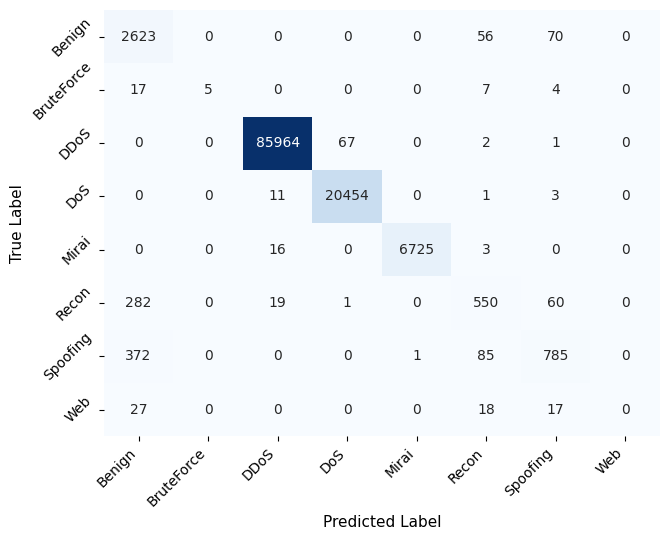

Completed GRU seed 42: test macro F1=0.689452
Saved run results to: /kaggle/working/CICIoT2023_GRU_5_seed_results/GRU_Seed_1

GRU: final run 2/5; seed=43
Epoch 1/100


2026-09-26 07:15:03.520535: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5539/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8351 - loss: 0.4108

2026-09-26 07:15:42.011028: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 45s 7ms/step - accuracy: 0.8617 - loss: 0.3122 - val_accuracy: 0.9221 - val_loss: 0.1833
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9588 - loss: 0.1104 - val_accuracy: 0.9830 - val_loss: 0.0572
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9850 - loss: 0.0491 - val_accuracy: 0.9884 - val_loss: 0.0375
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9869 - loss: 0.0426 - val_accuracy: 0.9889 - val_loss: 0.0360
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9871 - loss: 0.0398 - val_accuracy: 0.9893 - val_loss: 0.0339
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9874 - loss: 0.0385 - val_accuracy: 0.9884 - val_loss: 0.0350
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9880 - loss: 0.0369 - val_accuracy: 0.9892 - val_loss: 0.0331
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 40s 7ms/step - accuracy: 0.9880 - loss: 0.036

2026-09-26 07:35:53.547778: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 07:36:03.811166: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

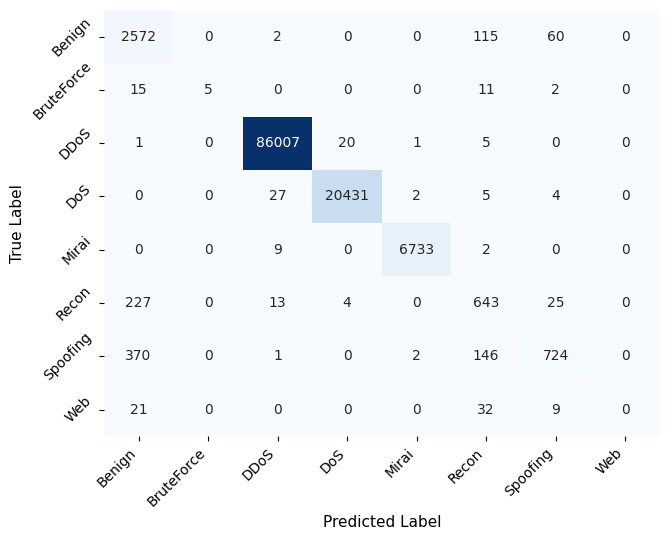

Completed GRU seed 43: test macro F1=0.688959
Saved run results to: /kaggle/working/CICIoT2023_GRU_5_seed_results/GRU_Seed_2

GRU: final run 3/5; seed=44
Epoch 1/100


2026-09-26 07:37:53.593574: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5536/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8364 - loss: 0.4094

2026-09-26 07:38:29.808644: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 42s 7ms/step - accuracy: 0.8602 - loss: 0.3150 - val_accuracy: 0.9142 - val_loss: 0.2090
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9481 - loss: 0.1329 - val_accuracy: 0.9846 - val_loss: 0.0531
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9844 - loss: 0.0514 - val_accuracy: 0.9877 - val_loss: 0.0388
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9863 - loss: 0.0442 - val_accuracy: 0.9888 - val_loss: 0.0359
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9875 - loss: 0.0399 - val_accuracy: 0.9891 - val_loss: 0.0344
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9876 - loss: 0.0382 - val_accuracy: 0.9889 - val_loss: 0.0337
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9880 - loss: 0.0368 - val_accuracy: 0.9892 - val_loss: 0.0324
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9879 - loss: 0.036

2026-09-26 07:53:53.962527: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 07:54:03.878874: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

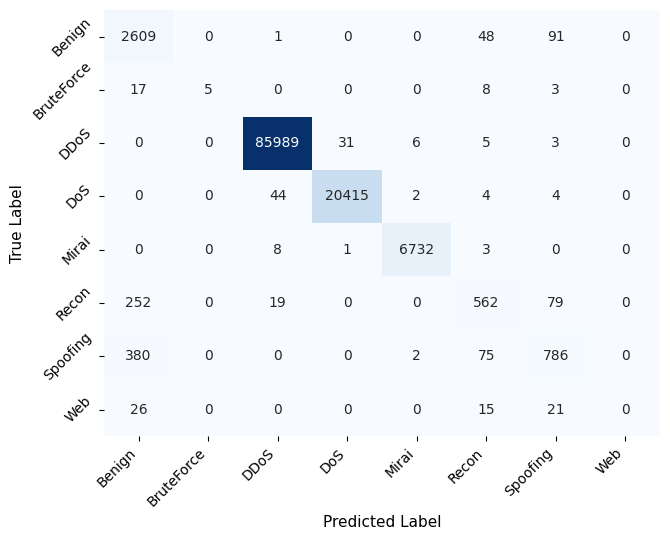

Completed GRU seed 44: test macro F1=0.689664
Saved run results to: /kaggle/working/CICIoT2023_GRU_5_seed_results/GRU_Seed_3

GRU: final run 4/5; seed=45
Epoch 1/100


2026-09-26 07:55:50.785825: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5534/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8382 - loss: 0.4022

2026-09-26 07:56:26.915728: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 42s 7ms/step - accuracy: 0.8631 - loss: 0.3082 - val_accuracy: 0.9241 - val_loss: 0.1867
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 36s 6ms/step - accuracy: 0.9519 - loss: 0.1266 - val_accuracy: 0.9856 - val_loss: 0.0510
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 36s 7ms/step - accuracy: 0.9848 - loss: 0.0499 - val_accuracy: 0.9884 - val_loss: 0.0381
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9869 - loss: 0.0420 - val_accuracy: 0.9885 - val_loss: 0.0353
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9874 - loss: 0.0397 - val_accuracy: 0.9886 - val_loss: 0.0345
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 36s 7ms/step - accuracy: 0.9877 - loss: 0.0389 - val_accuracy: 0.9892 - val_loss: 0.0326
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9880 - loss: 0.0370 - val_accuracy: 0.9896 - val_loss: 0.0320
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 37s 7ms/step - accuracy: 0.9883 - loss: 0.035

2026-09-26 08:15:19.111562: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 08:15:39.700718: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

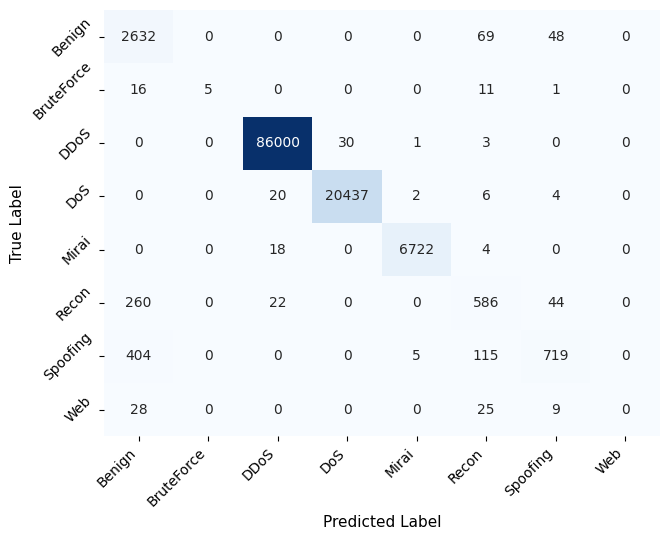

Completed GRU seed 45: test macro F1=0.686975
Saved run results to: /kaggle/working/CICIoT2023_GRU_5_seed_results/GRU_Seed_4

GRU: final run 5/5; seed=46
Epoch 1/100


2026-09-26 08:17:36.087041: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5539/5543 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8372 - loss: 0.4011

2026-09-26 08:18:12.415644: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


5543/5543 ━━━━━━━━━━━━━━━━━━━━ 42s 7ms/step - accuracy: 0.8607 - loss: 0.3114 - val_accuracy: 0.9075 - val_loss: 0.2110
Epoch 2/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9437 - loss: 0.1404 - val_accuracy: 0.9799 - val_loss: 0.0664
Epoch 3/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9841 - loss: 0.0519 - val_accuracy: 0.9876 - val_loss: 0.0392
Epoch 4/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9866 - loss: 0.0430 - val_accuracy: 0.9859 - val_loss: 0.0432
Epoch 5/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9872 - loss: 0.0398 - val_accuracy: 0.9889 - val_loss: 0.0333
Epoch 6/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 38s 7ms/step - accuracy: 0.9876 - loss: 0.0388 - val_accuracy: 0.9893 - val_loss: 0.0324
Epoch 7/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 39s 7ms/step - accuracy: 0.9882 - loss: 0.0367 - val_accuracy: 0.9894 - val_loss: 0.0316
Epoch 8/100
5543/5543 ━━━━━━━━━━━━━━━━━━━━ 41s 7ms/step - accuracy: 0.9883 - loss: 0.035

2026-09-26 08:38:34.380910: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
2026-09-26 08:38:44.780973: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

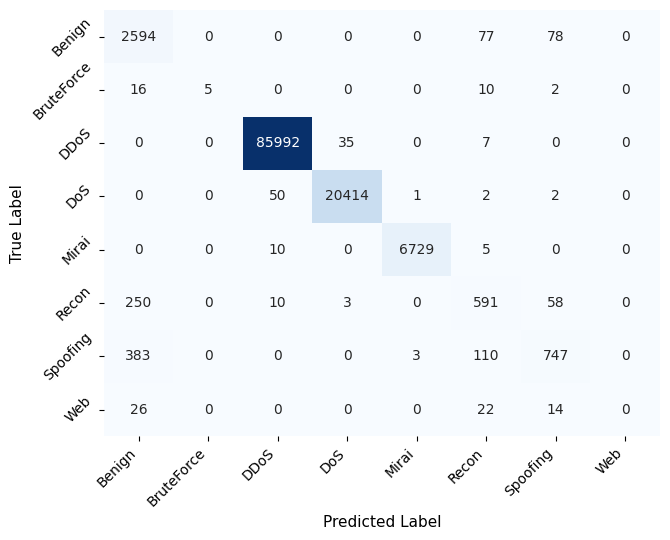

Completed GRU seed 46: test macro F1=0.687326
Saved run results to: /kaggle/working/CICIoT2023_GRU_5_seed_results/GRU_Seed_5


,Model,Run,Seed,Training_Time_s,Validation_F1_macro,Test_Loss,Accuracy,Precision_macro,Recall_macro,F1_macro,...,Recall_weighted,F1_weighted,MCC,ROC_AUC_macro_OvR,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,Throughput_samples_per_s
0,GRU,1,42,1691.175131,0.716702,0.030463,0.990359,0.797838,0.666990,0.689452,...,0.990359,0.989716,0.977960,0.997938,0.001371,0.001377,0.001326,9.667855,0.081761,12230.841363
1,GRU,2,43,1250.157638,0.715587,0.030355,0.990435,0.793607,0.671354,0.688959,...,0.990435,0.989880,0.978119,0.997950,0.001368,0.001366,0.001377,9.300618,0.078655,12713.778478
2,GRU,3,44,960.520874,0.713339,0.030749,0.990291,0.795935,0.668027,0.689664,...,0.990291,0.989675,0.977789,0.997852,0.001445,0.001387,0.001852,9.004246,0.076148,13132.248896
3,GRU,4,45,1168.434572,0.715604,0.030587,0.990317,0.796462,0.665590,0.686975,...,0.990317,0.989640,0.977858,0.997774,0.001408,0.001383,0.001580,9.871898,0.083486,11978.040673
4,GRU,5,46,1258.452192,0.712503,0.030510,0.990072,0.792070,0.667340,0.687326,...,0.990072,0.989468,0.977286,0.997628,0.001468,0.001418,0.001815,9.403731,0.079527,12574.371203


In [26]:
def run_five_seed_experiment(
    model_name,
    model_builder,
    parameters,
    X_train_input,
    X_val_input,
    X_test_input,
    max_epochs,
    batch_size_key,
):
    """Train, evaluate, time, and save the GRU model for five seeds."""

    labels = np.arange(
        number_of_classes
    )

    run_rows = []
    per_class_rows = []
    representative_candidates = []

    for run_number, seed in enumerate(
        RUN_SEEDS,
        start=1,
    ):
        print(
            "\n" + "=" * 72
        )
        print(
            f"{model_name}: final run "
            f"{run_number}/{N_FINAL_RUNS}; "
            f"seed={seed}"
        )
        print(
            "=" * 72
        )

        # ----------------------------------------------------
        # Separate output folder for this independent run.
        # GRU_Seed_1 ... GRU_Seed_10
        # ----------------------------------------------------
        seed_output_directory = (
            MODEL_OUTPUT_DIRECTORY
            / f"GRU_Seed_{run_number}"
        )

        seed_output_directory.mkdir(
            parents=True,
            exist_ok=True,
        )

        tf.keras.backend.clear_session()
        set_final_run_seed(seed)

        model = model_builder(
            parameters
        )

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------
        training_start = (
            time.perf_counter()
        )

        history = model.fit(
            X_train_input,
            y_train,
            epochs=max_epochs,
            batch_size=parameters[
                batch_size_key
            ],
            validation_data=(
                X_val_input,
                y_val,
            ),

            callbacks=[
                tf.keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=EARLY_STOPPING_PATIENCE,
                    restore_best_weights=True,
                )
            ],

            shuffle=True,
            verbose=1,
        )

        training_time = (
            time.perf_counter()
            - training_start
        )

        # ----------------------------------------------------
        # Validation macro F1
        # ----------------------------------------------------
        validation_probabilities = (
            model.predict(
                X_val_input,
                verbose=0,
            )
        )

        validation_predictions = (
            np.argmax(
                validation_probabilities,
                axis=1,
            )
        )

        validation_macro_f1 = f1_score(
            y_val,
            validation_predictions,
            labels=labels,
            average="macro",
            zero_division=0,
        )

        # ----------------------------------------------------
        # Test evaluation and timing
        # ----------------------------------------------------
        evaluation = model.evaluate(
            X_test_input,
            y_test,
            verbose=0,
            return_dict=True,
        )

        (
            test_probabilities,
            timing_metrics,
        ) = benchmark_full_test_prediction(
            model,
            X_test_input,
        )

        test_predictions = np.argmax(
            test_probabilities,
            axis=1,
        )

        test_metrics = calculate_test_metrics(
            y_test,
            test_predictions,
            test_probabilities,
            labels,
        )

        # ----------------------------------------------------
        # Scalar metrics
        # ----------------------------------------------------
        run_row = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "Training_Time_s": float(
                training_time
            ),
            "Validation_F1_macro": float(
                validation_macro_f1
            ),
            "Test_Loss": float(
                evaluation["loss"]
            ),
            **test_metrics,
            **timing_metrics,
        }

        run_rows.append(
            run_row
        )

        pd.DataFrame(
            [run_row]
        ).to_csv(
            seed_output_directory
            / "scalar_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable macro-only metrics.
        # ----------------------------------------------------
        macro_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_macro": run_row["Precision_macro"],
            "Recall_macro": run_row["Recall_macro"],
            "F1_macro": run_row["F1_macro"],
            "ROC_AUC_macro_OvR": run_row["ROC_AUC_macro_OvR"],
            "FPR_macro": run_row["FPR_macro"],
        }

        pd.DataFrame(
            [macro_metrics_row]
        ).to_csv(
            seed_output_directory
            / "macro_metrics.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Readable weighted-average metrics.
        # ----------------------------------------------------
        weighted_metrics_row = {
            "Model": run_row["Model"],
            "Run": run_row["Run"],
            "Seed": run_row["Seed"],
            "Precision_weighted": run_row["Precision_weighted"],
            "Recall_weighted": run_row["Recall_weighted"],
            "F1_weighted": run_row["F1_weighted"],
            "FPR_weighted": run_row["FPR_weighted"],
        }

        pd.DataFrame(
            [weighted_metrics_row]
        ).to_csv(
            seed_output_directory
            / "weighted_average_metrics.csv",
            index=False,
        )


        # ----------------------------------------------------
        # Full classification report
        # ----------------------------------------------------
        seed_classification_report = (
            classification_report(
                y_test,
                test_predictions,
                labels=labels,
                target_names=(
                    label_encoder.classes_
                ),
                output_dict=True,
                zero_division=0,
            )
        )

        pd.DataFrame(
            seed_classification_report
        ).transpose().to_csv(
            seed_output_directory
            / "classification_report.csv"
        )

        # ----------------------------------------------------
        # Per-class Precision / Recall / F1 / FPR
        # ----------------------------------------------------
        (
            precision_values,
            recall_values,
            f1_values,
            support_values,
        ) = precision_recall_fscore_support(
            y_test,
            test_predictions,
            labels=labels,
            zero_division=0,
        )

        class_confusion_matrices = (
            multilabel_confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_per_class_rows = []

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            (
                true_negative,
                false_positive,
                false_negative,
                true_positive,
            ) = class_confusion_matrices[
                class_index
            ].ravel()

            fpr_denominator = (
                false_positive
                + true_negative
            )

            class_fpr = (
                false_positive
                / fpr_denominator
                if fpr_denominator
                else 0.0
            )

            per_class_row = {
                "Model": model_name,
                "Run": run_number,
                "Seed": seed,
                "Class": class_name,
                "Precision": float(
                    precision_values[
                        class_index
                    ]
                ),
                "Recall": float(
                    recall_values[
                        class_index
                    ]
                ),
                "F1": float(
                    f1_values[
                        class_index
                    ]
                ),
                "FPR": float(
                    class_fpr
                ),
                "TP": int(
                    true_positive
                ),
                "TN": int(
                    true_negative
                ),
                "FP": int(
                    false_positive
                ),
                "FN": int(
                    false_negative
                ),
                "Support": int(
                    support_values[
                        class_index
                    ]
                ),
            }

            seed_per_class_rows.append(
                per_class_row
            )

            per_class_rows.append(
                per_class_row
            )

        pd.DataFrame(
            seed_per_class_rows
        ).to_csv(
            seed_output_directory
            / "per_class_metrics_and_fpr.csv",
            index=False,
        )

        # ----------------------------------------------------
        # FPR summary for this seed
        # ----------------------------------------------------
        pd.DataFrame(
            [
                {
                    "Model": model_name,
                    "Run": run_number,
                    "Seed": seed,
                    "FPR_macro": (
                        test_metrics[
                            "FPR_macro"
                        ]
                    ),
                    "FPR_micro_overall": (
                        test_metrics[
                            "FPR_micro_overall"
                        ]
                    ),
                    "FPR_weighted": (
                        test_metrics[
                            "FPR_weighted"
                        ]
                    ),
                }
            ]
        ).to_csv(
            seed_output_directory
            / "false_positive_rate_summary.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Confusion matrix: CSV + PDF + PNG
        # ----------------------------------------------------
        seed_confusion_matrix = (
            confusion_matrix(
                y_test,
                test_predictions,
                labels=labels,
            )
        )

        seed_confusion_matrix_df = (
            pd.DataFrame(
                seed_confusion_matrix,
                index=(
                    label_encoder.classes_
                ),
                columns=(
                    label_encoder.classes_
                ),
            )
        )

        seed_confusion_matrix_df.index.name = (
            "True_Label"
        )
        seed_confusion_matrix_df.columns.name = (
            "Predicted_Label"
        )

        seed_confusion_matrix_df.to_csv(
            seed_output_directory
            / "confusion_matrix.csv"
        )

        plot_publication_confusion_matrix(
            y_test,
            test_predictions,
            seed_output_directory
            / "confusion_matrix",
        )

        # ----------------------------------------------------
        # Training history
        # ----------------------------------------------------
        history_df = pd.DataFrame(
            history.history
        )

        history_df.index = (
            np.arange(
                1,
                len(history_df) + 1,
            )
        )
        history_df.index.name = (
            "Epoch"
        )

        history_df.to_csv(
            seed_output_directory
            / "training_history.csv"
        )

        # ----------------------------------------------------
        # Test predictions and probabilities
        # ----------------------------------------------------
        predictions_df = pd.DataFrame(
            {
                "True_Label_Encoded": (
                    y_test
                ),
                "Predicted_Label_Encoded": (
                    test_predictions
                ),
                "True_Label": (
                    label_encoder.inverse_transform(
                        y_test
                    )
                ),
                "Predicted_Label": (
                    label_encoder.inverse_transform(
                        test_predictions
                    )
                ),
            }
        )

        for (
            class_index,
            class_name,
        ) in enumerate(
            label_encoder.classes_
        ):
            predictions_df[
                f"Probability_{class_name}"
            ] = test_probabilities[
                :,
                class_index,
            ]

        predictions_df.to_csv(
            seed_output_directory
            / "test_predictions_and_probabilities.csv",
            index=False,
        )

        # ----------------------------------------------------
        # Save trained model
        # ----------------------------------------------------
        model_path = (
            seed_output_directory
            / f"{model_name.lower()}_seed_{seed}.keras"
        )

        model.save(
            model_path
        )

        # ----------------------------------------------------
        # Save run metadata and exact pre-stored parameters
        # ----------------------------------------------------
        run_metadata = {
            "Model": model_name,
            "Run": run_number,
            "Seed": seed,
            "N_Final_Runs": N_FINAL_RUNS,
            "Training_Samples": int(
                len(X_train_input)
            ),
            "Validation_Samples": int(
                len(X_val_input)
            ),
            "Test_Samples": int(
                len(X_test_input)
            ),
            "Hyperparameters": parameters,
        }

        with open(
            seed_output_directory
            / "run_metadata.json",
            "w",
            encoding="utf-8",
        ) as json_file:
            json.dump(
                run_metadata,
                json_file,
                indent=2,
            )

        representative_candidates.append(
            {
                "Seed": seed,
                "Run": run_number,
                "F1_macro": (
                    test_metrics[
                        "F1_macro"
                    ]
                ),
                "Predictions": (
                    test_predictions.copy()
                ),
            }
        )

        print(
            f"Completed {model_name} "
            f"seed {seed}: "
            f"test macro F1="
            f"{test_metrics['F1_macro']:.6f}"
        )

        print(
            "Saved run results to:",
            seed_output_directory.resolve(),
        )

        del history
        del model
        gc.collect()
        tf.keras.backend.clear_session()

    return (
        pd.DataFrame(
            run_rows
        ),
        pd.DataFrame(
            per_class_rows
        ),
        representative_candidates,
    )


# ============================================================
# GRU-only experiment definition
# Keep the original experiment-definition variable name.
# ============================================================
experiment_definitions = [
    {
        "model_name": "GRU",
        "model_builder": build_final_gru,
        "parameters": best_params_gru_03,
        "X_train_input": X_train_reshaped_GRU,
        "X_val_input": X_val_reshaped_GRU,
        "X_test_input": X_test_reshaped_GRU,
        "max_epochs": MAX_EPOCHS_GRU,
        "batch_size_key": "batch_size_gru",
    },
]


run_result_frames = []
per_class_result_frames = []
representative_candidates_by_model = {}


for experiment in experiment_definitions:
    (
        run_frame,
        class_frame,
        candidates,
    ) = run_five_seed_experiment(
        **experiment
    )

    run_result_frames.append(
        run_frame
    )
    per_class_result_frames.append(
        class_frame
    )

    representative_candidates_by_model[
        experiment["model_name"]
    ] = candidates


# Keep the original result-variable names.
all_run_results = pd.concat(
    run_result_frames,
    ignore_index=True,
)

all_per_class_results = pd.concat(
    per_class_result_frames,
    ignore_index=True,
)


all_run_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_5_seed_run_results.csv",
    index=False,
)

all_per_class_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_per_class_5_seed_run_results.csv",
    index=False,
)




# ============================================================
# Separate five-seed macro and weighted-average result tables.
# ============================================================
macro_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_metric_columns = [
    "Model",
    "Run",
    "Seed",
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_5_seed_results = (
    all_run_results[
        macro_metric_columns
    ].copy()
)

weighted_average_metrics_5_seed_results = (
    all_run_results[
        weighted_metric_columns
    ].copy()
)

macro_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_macro_metrics_5_seed_results.csv",
    index=False,
)

weighted_average_metrics_5_seed_results.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "gru_weighted_average_metrics_5_seed_results.csv",
    index=False,
)

display(
    all_run_results
)


### Mean ± sample standard deviation across the ten GRU seeds


In [27]:
identifier_columns = {
    "Model",
    "Run",
    "Seed",
}

metric_columns = [
    column
    for column in all_run_results.columns
    if column not in identifier_columns
]

summary_records = []


for (
    model_name,
    model_rows,
) in all_run_results.groupby(
    "Model",
    sort=False,
):
    for metric_name in metric_columns:
        metric_values = (
            model_rows[
                metric_name
            ].astype(float)
        )

        metric_mean = float(
            metric_values.mean()
        )

        metric_sd = float(
            metric_values.std(
                ddof=1
            )
        )

        summary_records.append(
            {
                "Model": model_name,
                "Metric": metric_name,
                "Mean": metric_mean,
                "SD": metric_sd,
                "N": int(
                    metric_values
                    .notna()
                    .sum()
                ),
                "Mean ± SD": format_mean_sd(
                    metric_mean,
                    metric_sd,
                ),
            }
        )


five_run_summary_long = pd.DataFrame(
    summary_records
)

five_run_summary_table = (
    five_run_summary_long.pivot(
        index="Model",
        columns="Metric",
        values="Mean ± SD",
    )
    .reindex(["GRU"])
)


# Backward-compatible aliases for downstream code that used the
# original five-run variable names.
five_run_summary_long = (
    five_run_summary_long
)
five_run_summary_table = (
    five_run_summary_table
)


five_run_summary_long.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_long.csv",
    index=False,
)

five_run_summary_table.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "five_run_mean_sd_report_table.csv"
)




# ============================================================
# Separate mean ± SD tables for macro and weighted metrics.
# ============================================================
macro_summary_metric_names = [
    "Precision_macro",
    "Recall_macro",
    "F1_macro",
    "ROC_AUC_macro_OvR",
    "FPR_macro",
]

weighted_summary_metric_names = [
    "Precision_weighted",
    "Recall_weighted",
    "F1_weighted",
    "FPR_weighted",
]

macro_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            macro_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

weighted_average_metrics_mean_sd = (
    five_run_summary_long[
        five_run_summary_long[
            "Metric"
        ].isin(
            weighted_summary_metric_names
        )
    ][
        [
            "Model",
            "Metric",
            "Mean",
            "SD",
            "N",
            "Mean ± SD",
        ]
    ].reset_index(
        drop=True
    )
)

macro_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "macro_metrics_5_seed_mean_sd.csv",
    index=False,
)

weighted_average_metrics_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "weighted_average_metrics_5_seed_mean_sd.csv",
    index=False,
)

print(
    "Macro metrics — 5-run mean ± sample SD:"
)
display(
    macro_metrics_mean_sd
)

print(
    "Weighted-average metrics — 5-run mean ± sample SD:"
)
display(
    weighted_average_metrics_mean_sd
)

print(
    "Five-run GRU journal report "
    "(mean ± sample SD; n = 5):"
)

display(
    five_run_summary_table
)


Macro metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,GRU,Precision_macro,0.795182,0.002314,5,0.795182 ± 0.002314
1,GRU,Recall_macro,0.667860,0.002146,5,0.667860 ± 0.002146
2,GRU,F1_macro,0.688475,0.001242,5,0.688475 ± 0.001242
3,GRU,ROC_AUC_macro_OvR,0.997828,0.000133,5,0.997828 ± 0.000133
4,GRU,FPR_macro,0.001412,0.000044,5,0.001412 ± 0.000044


Weighted-average metrics — 5-run mean ± sample SD:


,Model,Metric,Mean,SD,N,Mean ± SD
0,GRU,Precision_weighted,0.990050,0.000242,5,0.990050 ± 0.000242
1,GRU,Recall_weighted,0.990295,0.000136,5,0.990295 ± 0.000136
2,GRU,F1_weighted,0.989676,0.000148,5,0.989676 ± 0.000148
3,GRU,FPR_weighted,0.001590,0.000242,5,0.001590 ± 0.000242


Five-run GRU journal report (mean ± sample SD; n = 5):


Metric,Accuracy,F1_macro,F1_weighted,FPR_macro,FPR_micro_overall,FPR_weighted,Inference_Time_s,Latency_ms_per_sample,MCC,Precision_macro,Precision_weighted,ROC_AUC_macro_OvR,Recall_macro,Recall_weighted,Test_Loss,Throughput_samples_per_s,Training_Time_s,Validation_F1_macro
Model,,,,,,,,,,,,,,,,,,
GRU,0.990295 ± 0.000136,0.688475 ± 0.001242,0.989676 ± 0.000148,0.001412 ± 0.000044,0.001386 ± 0.000019,0.001590 ± 0.000242,9.449670 ± 0.334892,0.079915 ± 0.002832,0.977802 ± 0.000314,0.795182 ± 0.002314,0.990050 ± 0.000242,0.997828 ± 0.000133,0.667860 ± 0.002146,0.990295 ± 0.000136,0.030533 ± 0.000147,12525.856123 ± 445.116893,1265.748082 ± 266.419797,0.714747 ± 0.001752


### Per-class mean ± sample standard deviation

FPR is included together with Precision, Recall, and F1.


In [28]:
per_class_summary_records = []


for (
    model_name,
    class_name,
), class_rows in (
    all_per_class_results.groupby(
        ["Model", "Class"],
        sort=False,
    )
):
    record = {
        "Model": model_name,
        "Class": class_name,
        "Support": int(
            class_rows[
                "Support"
            ].iloc[0]
        ),
        "N": int(
            len(class_rows)
        ),
    }

    for metric_name in [
        "Precision",
        "Recall",
        "F1",
        "FPR",
    ]:
        metric_mean = float(
            class_rows[
                metric_name
            ].mean()
        )

        metric_sd = float(
            class_rows[
                metric_name
            ].std(ddof=1)
        )

        record[
            f"{metric_name}_Mean"
        ] = metric_mean

        record[
            f"{metric_name}_SD"
        ] = metric_sd

        record[
            f"{metric_name}_Mean ± SD"
        ] = format_mean_sd(
            metric_mean,
            metric_sd,
        )

    per_class_summary_records.append(
        record
    )


# Keep the original summary variable name.
per_class_mean_sd = pd.DataFrame(
    per_class_summary_records
)


per_class_mean_sd.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "per_class_five_run_mean_sd.csv",
    index=False,
)


display(
    per_class_mean_sd
)


,Model,Class,Support,N,Precision_Mean,Precision_SD,Precision_Mean ± SD,Recall_Mean,Recall_SD,Recall_Mean ± SD,F1_Mean,F1_SD,F1_Mean ± SD,FPR_Mean,FPR_SD,FPR_Mean ± SD
0,GRU,Benign,2749,5,0.793613,0.005497,0.793613 ± 0.005497,0.947981,0.008673,0.947981 ± 0.008673,0.863912,0.001099,0.863912 ± 0.001099,0.005870,0.000247,0.005870 ± 0.000247
1,GRU,BruteForce,33,5,1.000000,0.000000,1.000000 ± 0.000000,0.151515,0.000000,0.151515 ± 0.000000,0.263158,0.000000,0.263158 ± 0.000000,0.000000,0.000000,0.000000 ± 0.000000
2,GRU,DDoS,86034,5,0.999303,0.000130,0.999303 ± 0.000130,0.999493,0.000190,0.999493 ± 0.000190,0.999398,0.000096,0.999398 ± 0.000096,0.001863,0.000348,0.001863 ± 0.000348
3,GRU,DoS,20469,5,0.998125,0.000840,0.998125 ± 0.000840,0.998104,0.000813,0.998104 ± 0.000813,0.998114,0.000350,0.998114 ± 0.000350,0.000393,0.000177,0.000393 ± 0.000177
4,GRU,Mirai,6744,5,0.999169,0.000520,0.999169 ± 0.000520,0.997657,0.000691,0.997657 ± 0.000691,0.998412,0.000391,0.998412 ± 0.000391,0.000050,0.000031,0.000050 ± 0.000031
5,GRU,Recon,912,5,0.729112,0.043232,0.729112 ± 0.043232,0.642982,0.039326,0.642982 ± 0.039326,0.681439,0.006619,0.681439 ± 0.006619,0.001895,0.000533,0.001895 ± 0.000533
6,GRU,Spoofing,1243,5,0.842139,0.033585,0.842139 ± 0.033585,0.605149,0.025891,0.605149 ± 0.025891,0.703369,0.009590,0.703369 ± 0.009590,0.001224,0.000354,0.001224 ± 0.000354
7,GRU,Web,62,5,0.000000,0.000000,0.000000 ± 0.000000,0.000000,0.000000,0.000000 ± 0.000000,0.000000,0.000000,0.000000 ± 0.000000,0.000000,0.000000,0.000000 ± 0.000000


### Representative GRU confusion matrix

The representative run is the seed whose test macro F1 is closest to the
5-run GRU mean. This follows the selection principle used in the original
five-run code.


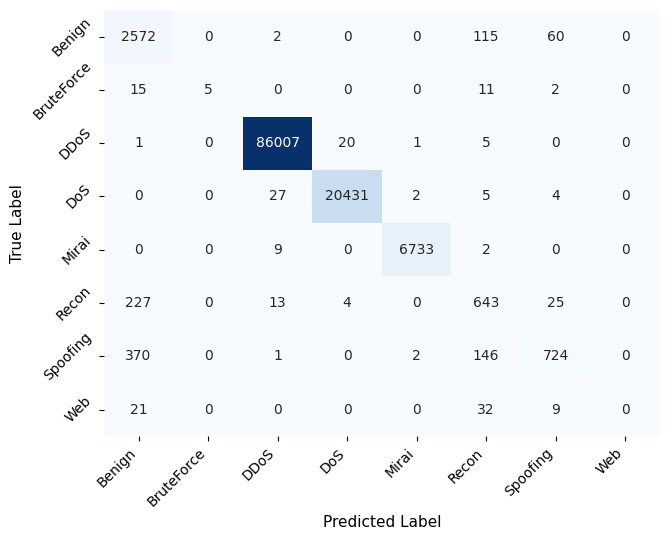

,Model,Representative_Run,Representative_Seed,Representative_F1_macro,Five_Run_Mean_F1_macro
0,GRU,2,43,0.688959,0.688475


All five-run GRU outputs were saved:


In [29]:
representative_run_records = []


for model_name in ["GRU"]:
    candidates = (
        representative_candidates_by_model[
            model_name
        ]
    )

    model_mean_f1 = float(
        all_run_results.loc[
            all_run_results[
                "Model"
            ] == model_name,
            "F1_macro",
        ].mean()
    )

    representative = min(
        candidates,
        key=lambda item: abs(
            item["F1_macro"]
            - model_mean_f1
        ),
    )

    representative_run_records.append(
        {
            "Model": model_name,
            "Representative_Run": (
                representative["Run"]
            ),
            "Representative_Seed": (
                representative["Seed"]
            ),
            "Representative_F1_macro": (
                representative[
                    "F1_macro"
                ]
            ),
            "Five_Run_Mean_F1_macro": (
                model_mean_f1
            ),
        }
    )

    output_stem = (
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_confusion_matrix"
        )
    )

    plot_publication_confusion_matrix(
        y_test,
        representative[
            "Predictions"
        ],
        output_stem,
    )

    representative_report = (
        classification_report(
            y_test,
            representative[
                "Predictions"
            ],
            labels=np.arange(
                number_of_classes
            ),
            target_names=(
                label_encoder.classes_
            ),
            output_dict=True,
            zero_division=0,
        )
    )

    pd.DataFrame(
        representative_report
    ).transpose().to_csv(
        REPORT_OUTPUT_DIRECTORY
        / (
            f"{model_name.lower()}_"
            "representative_classification_report.csv"
        )
    )


# Keep the original result-variable name.
representative_runs = pd.DataFrame(
    representative_run_records
)

representative_runs.to_csv(
    REPORT_OUTPUT_DIRECTORY
    / "representative_runs.csv",
    index=False,
)


display(
    representative_runs
)

print(
    "All five-run GRU outputs were saved:"
)


In [30]:
import shutil

# Compress the entire Kaggle working/output directory
shutil.make_archive(
    "/kaggle/working/CICIoT2023_Feature_Augmented_GRU_5_Seeds_V2",
    "zip",
    "/kaggle/working"
)

print("Created: /kaggle/working/CICIoT2023_Feature_Augmented_GRU_5_Seeds_V2.zip")

Created: /kaggle/working/CICIoT2023_Feature_Augmented_GRU_5_Seeds_V2.zip
